## Assignment 3 - Robynne Le Roux

### Imports

In [57]:
import os
import string
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.preprocessing import LabelEncoder

### 1. Data processing 

In [29]:
'''minimal preprocessing ( lowercasing, punctuation removal, and whitespace trimming) to standardise the text while preserving word-level distinctions'''
def clean_text(text):
    
    if pd.isna(text):  # handle missing values
        return ""
    text = text.lower().strip() # convert to lowercase and remove leading/trailing whitespace in one go
    text = text.translate(str.maketrans('', '', string.punctuation))  # remove punctuation
    return text

def load_and_clean(lang, split):
    
    path = os.path.join(base_path, lang, f"{split}.tsv")
    df = pd.read_csv(path, sep='\t') # read TSV file into DataFrame
    
    df['full_text'] = df['headline'].fillna('') + ' ' + df['text'].fillna('') # combine headline and article text into one column
    df['clean_text'] = df['full_text'].apply(clean_text) # apply cleaning to combined text
    
    return df
    
def fit_all_vectorisers(texts): #had to change this to avoid shape mismatch errors
    #tokenisation
    #convert numerical vectors
    
    vec_bow = CountVectorizer() # Bag-of-Words: counts word frequencies
    vec_bin = CountVectorizer(binary=True) # Binary: marks presence/absence of words
    vec_tfidf = TfidfVectorizer() # TF-IDF: scales word importance across documents

    bow = vec_bow.fit_transform(texts) #used ai to help find this function from scikit-learn’s vectorisers
    binary = vec_bin.fit_transform(texts)
    tfidf = vec_tfidf.fit_transform(texts)

    return (vec_bow, vec_bin, vec_tfidf), (bow, binary, tfidf)

def transform_all_vectorisers(vecs, texts):
    
    vec_bow, vec_bin, vec_tfidf = vecs

    bow = vec_bow.transform(texts)
    binary = vec_bin.transform(texts)
    tfidf = vec_tfidf.transform(texts)

    return bow, binary, tfidf

base_path = "data"
langs = ['eng', 'xho']
splits = ['train', 'dev', 'test']

data = {}
vectorisers = {}

for lang in langs:
    
    data[lang] = {}
    
    for split in splits:
        
        df_train = load_and_clean(lang, 'train') # load and clean data
        vecs, train_vectors = fit_all_vectorisers(df_train['clean_text'])

    data[lang]['train'] = {
        'df': df_train,
        'bow': train_vectors[0],
        'binary': train_vectors[1],
        'tfidf': train_vectors[2]
    }

    vectorisers[lang] = vecs  # Save fitted vectorisers for reuse

    # Load and transform dev/test using the same vectorisers
    for split in ['dev', 'test']:
        df_split = load_and_clean(lang, split)
        split_vectors = transform_all_vectorisers(vecs, df_split['clean_text'])

        data[lang][split] = {
            'df': df_split,
            'bow': split_vectors[0],
            'binary': split_vectors[1],
            'tfidf': split_vectors[2]
        }

### Check Data processing Correcrt

In [31]:
# Check structure for one example
lang = 'eng'
split = 'train'

df = data[lang][split]['df']
print(f"{lang.upper()} {split.upper()} \nRows: {len(df)}")
print("Columns:", df.columns.tolist())
print("\nSample cleaned text:")
print(df['clean_text'].head(3).to_string(index=False))

# Check vector shapes
bow = data[lang][split]['bow']
binary = data[lang][split]['binary']
tfidf = data[lang][split]['tfidf']

print(f"\nVector shapes for {lang}/{split}:")
print("Bag-of-Words:", bow.shape)
print("Binary:", binary.shape)
print("TF-IDF:", tfidf.shape)

ENG TRAIN 
Rows: 3309
Columns: ['category', 'headline', 'text', 'url', 'full_text', 'clean_text']

Sample cleaned text:
we havent had a single penny from the post offi...
redcar regent cinema new venue to open on frida...
dorset county hospital stands down critical inc...

Vector shapes for eng/train:
Bag-of-Words: (3309, 50456)
Binary: (3309, 50456)
TF-IDF: (3309, 50456)


### 2. Multinomial logistic regression implementation

In [32]:
'''adapted some code from tut'''
class MultinomialLogisticRegression(nn.Module): 
    
    def __init__(self, input_size, num_classes): #Initialises a single linear layer: this is the core of multinomial logistic regression.
        
        #input_size is the number of features (e.g. TF-IDF dimensions)
        #num_classes is the number of output categories
        
        super(MultinomialLogisticRegression, self).__init__()
        self.linear = nn.Linear(input_size, num_classes)

    def forward(self, feature): #Used during training — returns raw logits before softmax.
        
        output = self.linear(feature)
        return output

    def compute_probabilities(self, x): #Applies softmax to logits to produce class probabilities ie for evaluation
        
        logits = self.linear(x)
        return F.softmax(logits, dim = 1)  # apply softmax to get class probabilities

    def predict(self, x): #for evaluation
        
        probs = self.compute_probabilities(x) 
        return torch.argmax(probs, dim = 1) # return predicted class indices

model = MultinomialLogisticRegression(input_size = 784, num_classes = 10)
images = torch.rand(64, 784)  # batch of 64 flattened images

logits = model(images)  # for training
probs = model.compute_probabilities(images)  # for analysis
preds = model.predict(images)  # for evaluation

### 3. Training

In [39]:
'''adapted from perceptron'''
def train_model(model, X_train, y_train, X_val=None, y_val=None,
                max_epochs=50, batch_size=32, learning_rate=0.01,
                error_threshold=None, stop_on_val=False, seed=42):
    """Train multinomial logistic regression with full metric logging and optional early stopping."""
    
    torch.manual_seed(seed)
    optimizer = optim.SGD(model.parameters(), lr=learning_rate)
    criterion = nn.CrossEntropyLoss()
    history = []

    for epoch in range(1, max_epochs + 1):
        # Shuffle training data
        idx = torch.randperm(X_train.size(0))
        X_train = X_train[idx]
        y_train = y_train[idx]

        model.train()
        epoch_loss = 0.0

        for i in range(0, X_train.size(0), batch_size):
            x_batch = X_train[i:i+batch_size]
            y_batch = y_train[i:i+batch_size]

            optimizer.zero_grad()
            logits = model(x_batch)
            loss = criterion(logits, y_batch)
            loss.backward()
            optimizer.step()

            epoch_loss += loss.item()

        avg_loss = epoch_loss / (X_train.size(0) // batch_size)

        # Evaluate accuracy
        model.eval()
        with torch.no_grad():
            train_preds = model.predict(X_train)
            train_acc = (train_preds == y_train).float().mean().item()

            if X_val is not None and y_val is not None:
                val_preds = model.predict(X_val)
                val_acc = (val_preds == y_val).float().mean().item()
            else:
                val_acc = None

        history.append((avg_loss, train_acc, val_acc))

        # Print all metrics per epoch
        if val_acc is not None:
            print(f"Epoch {epoch}: Loss={avg_loss:.4f}, Train Acc={train_acc:.3f}, Val Acc={val_acc:.3f}")
        else:
            print(f"Epoch {epoch}: Loss={avg_loss:.4f}, Train Acc={train_acc:.3f}")

        # Early stopping based on validation accuracy
        if stop_on_val and val_acc is not None and val_acc >= (1 - error_threshold):
            print(f"Stopped early at epoch {epoch} (Val Acc ≥ {1 - error_threshold:.2f})")
            break

    return history

# English training and validation sets
print("english training:")

df_train_eng = data['eng']['train']['df']
df_val_eng = data['eng']['dev']['df']

X_train_eng = torch.tensor(data['eng']['train']['tfidf'].toarray(), dtype=torch.float32)
X_val_eng = torch.tensor(data['eng']['dev']['tfidf'].toarray(), dtype=torch.float32)

label_encoder_eng = LabelEncoder()
y_train_eng = torch.tensor(label_encoder_eng.fit_transform(df_train_eng['category']), dtype=torch.long)
y_val_eng = torch.tensor(label_encoder_eng.transform(df_val_eng['category']), dtype=torch.long)

# Fixed Epochs
print("Stopping criterion: Fixed number of epochs (50)")
model_eng_fixed = MultinomialLogisticRegression(input_size=X_train_eng.shape[1], num_classes=len(label_encoder_eng.classes_))
history_eng_fixed = train_model(model_eng_fixed, X_train_eng, y_train_eng, X_val_eng, y_val_eng, max_epochs=50, batch_size=32, learning_rate=0.01, error_threshold=0.05, stop_on_val=False)

model_eng_fixed.eval()
with torch.no_grad():
    preds_eng_fixed = model_eng_fixed.predict(X_val_eng)
    acc_eng_fixed = (preds_eng_fixed == y_val_eng).float().mean().item()
print(f"Final Validation Accuracy (ENGLISH, Fixed Epochs): {acc_eng_fixed:.3f}")

# Early Stopping
print("\nStopping criterion: Early stopping based on validation accuracy (Val Acc ≥ 95%)")
model_eng_early = MultinomialLogisticRegression(input_size=X_train_eng.shape[1], num_classes=len(label_encoder_eng.classes_))
history_eng_early = train_model(model_eng_early, X_train_eng, y_train_eng, X_val_eng, y_val_eng,max_epochs=50, batch_size=32, learning_rate=0.01,error_threshold=0.05, stop_on_val=True)

model_eng_early.eval()
with torch.no_grad():
    preds_eng_early = model_eng_early.predict(X_val_eng)
    acc_eng_early = (preds_eng_early == y_val_eng).float().mean().item()
print(f"Final Validation Accuracy (ENGLISH, Early Stopping): {acc_eng_early:.3f}")


print("isixhosa training:")

# Prepare data
df_train_xho = data['xho']['train']['df']
df_val_xho = data['xho']['dev']['df']

X_train_xho = torch.tensor(data['xho']['train']['tfidf'].toarray(), dtype=torch.float32)
X_val_xho = torch.tensor(data['xho']['dev']['tfidf'].toarray(), dtype=torch.float32)

label_encoder_xho = LabelEncoder()
y_train_xho = torch.tensor(label_encoder_xho.fit_transform(df_train_xho['category']), dtype=torch.long)
y_val_xho = torch.tensor(label_encoder_xho.transform(df_val_xho['category']), dtype=torch.long)

# Fixed Epochs
print("Stopping criterion: Fixed number of epochs (50)")
model_xho_fixed = MultinomialLogisticRegression(input_size=X_train_xho.shape[1], num_classes=len(label_encoder_xho.classes_))
history_xho_fixed = train_model(model_xho_fixed, X_train_xho, y_train_xho, X_val_xho, y_val_xho, max_epochs=50, batch_size=32, learning_rate=0.01, error_threshold=0.05, stop_on_val=False)

model_xho_fixed.eval()
with torch.no_grad():
    preds_xho_fixed = model_xho_fixed.predict(X_val_xho)
    acc_xho_fixed = (preds_xho_fixed == y_val_xho).float().mean().item()
print(f"Final Validation Accuracy (ISIXHOSA, Fixed Epochs): {acc_xho_fixed:.3f}")

# Early Stopping
print("\nStopping criterion: Early stopping based on validation accuracy (Val Acc ≥ 95%)")
model_xho_early = MultinomialLogisticRegression(input_size=X_train_xho.shape[1], num_classes=len(label_encoder_xho.classes_))
history_xho_early = train_model(model_xho_early, X_train_xho, y_train_xho, X_val_xho, y_val_xho, max_epochs=50, batch_size=32, learning_rate=0.01, error_threshold=0.05, stop_on_val=True)

model_xho_early.eval()
with torch.no_grad():
    preds_xho_early = model_xho_early.predict(X_val_xho)
    acc_xho_early = (preds_xho_early == y_val_xho).float().mean().item()
print(f"Final Validation Accuracy (ISIXHOSA, Early Stopping): {acc_xho_early:.3f}")

english training:
Stopping criterion: Fixed number of epochs (50)
Epoch 1: Loss=1.8059, Train Acc=0.212, Val Acc=0.212
Epoch 2: Loss=1.7996, Train Acc=0.212, Val Acc=0.212
Epoch 3: Loss=1.7942, Train Acc=0.212, Val Acc=0.212
Epoch 4: Loss=1.7893, Train Acc=0.212, Val Acc=0.212
Epoch 5: Loss=1.7852, Train Acc=0.212, Val Acc=0.212
Epoch 6: Loss=1.7811, Train Acc=0.212, Val Acc=0.212
Epoch 7: Loss=1.7773, Train Acc=0.212, Val Acc=0.212
Epoch 8: Loss=1.7734, Train Acc=0.212, Val Acc=0.212
Epoch 9: Loss=1.7699, Train Acc=0.212, Val Acc=0.212
Epoch 10: Loss=1.7658, Train Acc=0.212, Val Acc=0.212
Epoch 11: Loss=1.7620, Train Acc=0.212, Val Acc=0.212
Epoch 12: Loss=1.7591, Train Acc=0.214, Val Acc=0.212
Epoch 13: Loss=1.7556, Train Acc=0.218, Val Acc=0.216
Epoch 14: Loss=1.7519, Train Acc=0.222, Val Acc=0.225
Epoch 15: Loss=1.7487, Train Acc=0.231, Val Acc=0.229
Epoch 16: Loss=1.7454, Train Acc=0.242, Val Acc=0.235
Epoch 17: Loss=1.7417, Train Acc=0.249, Val Acc=0.239
Epoch 18: Loss=1.7386, Tr

### 4. Hyperparameter tuning 

In [40]:
learning_rates = [0.001, 0.01, 0.1] #kept it simple as ran out of time
batch_sizes = [16, 32, 64]

print("Hyperparameter Tuning")

results = []

# Try each combination manually using nested loops
for lr in learning_rates:
    
    for bs in batch_sizes:
        
        print(f"ENGLISH: Learning rate={lr}, Batch size={bs} ---")
        model_eng_tune = MultinomialLogisticRegression(
            input_size=X_train_eng.shape[1],
            num_classes=len(label_encoder_eng.classes_)
        )

        history_eng_tune = train_model(
            model_eng_tune,
            X_train_eng, y_train_eng,
            X_val_eng, y_val_eng,
            max_epochs=50,
            batch_size=bs,
            learning_rate=lr,
            stop_on_val=False
        )

        val_acc_eng = history_eng_tune[-1][2]
        results.append(("English", lr, bs, val_acc_eng))
        print(f"Validation Accuracy (English): {val_acc_eng:.3f}")

        print(f"ISIXHOSA: Learning rate={lr}, Batch size={bs}")
        model_xho_tune = MultinomialLogisticRegression(
            input_size=X_train_xho.shape[1],
            num_classes=len(label_encoder_xho.classes_)
        )

        history_xho_tune = train_model(
            model_xho_tune,
            X_train_xho, y_train_xho,
            X_val_xho, y_val_xho,
            max_epochs=50,
            batch_size=bs,
            learning_rate=lr,
            stop_on_val=False
        )

        val_acc_xho = history_xho_tune[-1][2]
        results.append(("isiXhosa", lr, bs, val_acc_xho))
        print(f"Validation Accuracy (isiXhosa): {val_acc_xho:.3f}")

# Show summary of all results
print("Grid Search Results")
for lang, lr, bs, acc in results:
    print(f"{lang:8s} LR={lr:<5} Batch={bs:<3} Val Acc={acc:.3f}")

Hyperparameter Tuning

--- ENGLISH: Learning rate=0.001, Batch size=16 ---
Epoch 1: Loss=1.7998, Train Acc=0.233, Val Acc=0.225
Epoch 2: Loss=1.7984, Train Acc=0.212, Val Acc=0.212
Epoch 3: Loss=1.7970, Train Acc=0.212, Val Acc=0.212
Epoch 4: Loss=1.7956, Train Acc=0.212, Val Acc=0.212
Epoch 5: Loss=1.7944, Train Acc=0.212, Val Acc=0.212
Epoch 6: Loss=1.7931, Train Acc=0.212, Val Acc=0.212
Epoch 7: Loss=1.7919, Train Acc=0.212, Val Acc=0.212
Epoch 8: Loss=1.7907, Train Acc=0.212, Val Acc=0.212
Epoch 9: Loss=1.7896, Train Acc=0.212, Val Acc=0.212
Epoch 10: Loss=1.7885, Train Acc=0.212, Val Acc=0.212
Epoch 11: Loss=1.7874, Train Acc=0.212, Val Acc=0.212
Epoch 12: Loss=1.7864, Train Acc=0.212, Val Acc=0.212
Epoch 13: Loss=1.7854, Train Acc=0.212, Val Acc=0.212
Epoch 14: Loss=1.7844, Train Acc=0.212, Val Acc=0.212
Epoch 15: Loss=1.7834, Train Acc=0.212, Val Acc=0.212
Epoch 16: Loss=1.7825, Train Acc=0.212, Val Acc=0.212
Epoch 17: Loss=1.7815, Train Acc=0.212, Val Acc=0.212
Epoch 18: Loss=1

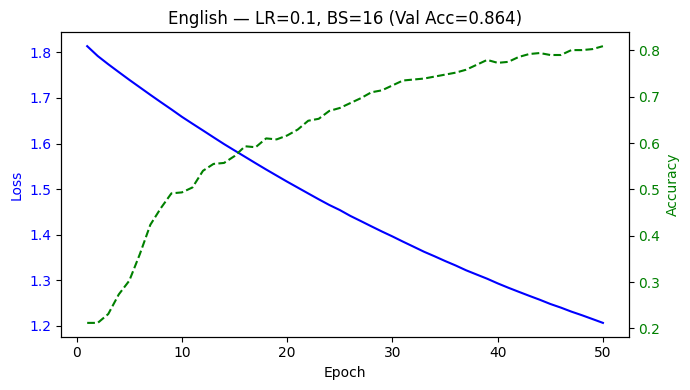

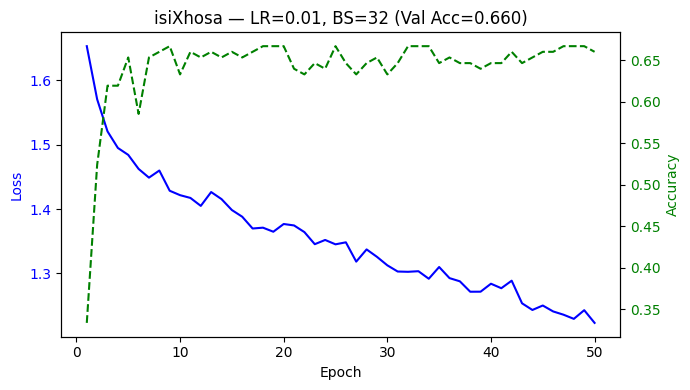

In [58]:
def plot_loss_curves(history, title):
    epochs = range(1, len(history) + 1)
    train_loss = [h[0] for h in history]  # training loss
    val_acc = [h[2] for h in history]     # validation accuracy

    fig, ax1 = plt.subplots(figsize=(7, 4))

    ax1.plot(epochs, train_loss, 'b-', label="Training Loss")
    ax1.set_xlabel("Epoch")
    ax1.set_ylabel("Loss", color='b')
    ax1.tick_params(axis='y', labelcolor='b')

    ax2 = ax1.twinx()
    ax2.plot(epochs, val_acc, 'g--', label="Validation Accuracy")
    ax2.set_ylabel("Accuracy", color='g')
    ax2.tick_params(axis='y', labelcolor='g')

    plt.title(title)
    fig.tight_layout()
    plt.show()

plot_loss_curves(history_eng_tune, "English — LR=0.1, BS=16 (Val Acc=0.864)")
plot_loss_curves(history_xho_tune, "isiXhosa — LR=0.01, BS=32 (Val Acc=0.660)")

### 5. Feature extraction 

In [59]:
def extract_features(texts, method="tfidf", max_features=5000, min_df=5):
    # Choose vectoriser based on method
    if method == "bow":
        vectorizer = CountVectorizer(max_features=max_features, min_df=min_df)
    elif method == "binary":
        vectorizer = CountVectorizer(binary=True, max_features=max_features, min_df=min_df)
    elif method == "tfidf":
        vectorizer = TfidfVectorizer(max_features=max_features, min_df=min_df)
    else:
        raise ValueError("Invalid method")
    
    # Fit and transform the training texts
    X = vectorizer.fit_transform(texts)
    return X, vectorizer

# Fixed hyperparameters for each language (based on tuning)
best_hparams = {
    "eng": {"lr": 0.1, "bs": 16},
    "xho": {"lr": 0.01, "bs": 32}
}

# Feature extraction methods to compare
feature_methods = ["bow", "binary", "tfidf"]

# Store results for summary later
results = []

# Loop through each language
for lang in ["eng", "xho"]:
    print()
    print("Language", lang.upper())

    # Load train/dev/test splits
    df_train = data[lang]["train"]["df"]
    df_val = data[lang]["dev"]["df"]
    df_test = data[lang]["test"]["df"]

    # Encode labels
    label_encoder = LabelEncoder()
    y_train = torch.tensor(label_encoder.fit_transform(df_train["category"]), dtype=torch.long)
    y_val = torch.tensor(label_encoder.transform(df_val["category"]), dtype=torch.long)
    y_test = torch.tensor(label_encoder.transform(df_test["category"]), dtype=torch.long)

    # Try each feature extraction method
    for method in feature_methods:
        print()
        print("Feature method", method.upper())

        # Extract features with vocab control
        X_train_raw, vectorizer = extract_features(df_train["text"], method=method)
        X_val_raw = vectorizer.transform(df_val["text"])
        X_test_raw = vectorizer.transform(df_test["text"])

        # Convert to PyTorch tensors
        X_train = torch.tensor(X_train_raw.toarray(), dtype=torch.float32)
        X_val = torch.tensor(X_val_raw.toarray(), dtype=torch.float32)
        X_test = torch.tensor(X_test_raw.toarray(), dtype=torch.float32)

        # Create and train model using best hyperparameters
        model = MultinomialLogisticRegression(
            input_size=X_train.shape[1],
            num_classes=len(label_encoder.classes_)
        )

        history = train_model(
            model,
            X_train, y_train,
            X_val, y_val,
            max_epochs=50,
            batch_size=best_hparams[lang]["bs"],
            learning_rate=best_hparams[lang]["lr"],
            error_threshold=0.05,
            stop_on_val=False
        )

        # Get final validation accuracy
        val_acc = history[-1][2]

        # Evaluate on test set
        model.eval()
        with torch.no_grad():
            test_preds = model.predict(X_test)
            test_acc = (test_preds == y_test).float().mean().item()

        # Save results
        results.append((lang, method, val_acc, test_acc))

        # Print outcome
        print("Validation accuracy", round(val_acc, 3))
        print("Test accuracy", round(test_acc, 3))

print()
print("Feature Extraction Summary")
print("Language  Method   Val Acc  Test Acc")
for lang, method, val_acc, test_acc in results:
    print(lang.ljust(9), method.ljust(8), round(val_acc, 3), round(test_acc, 3))


Language ENG

Feature method BOW
Epoch 1: Loss=25.2059, Train Acc=0.401, Val Acc=0.381
Epoch 2: Loss=6.0063, Train Acc=0.790, Val Acc=0.788
Epoch 3: Loss=4.1590, Train Acc=0.876, Val Acc=0.839
Epoch 4: Loss=2.2129, Train Acc=0.866, Val Acc=0.837
Epoch 5: Loss=1.7359, Train Acc=0.851, Val Acc=0.826
Epoch 6: Loss=2.4661, Train Acc=0.875, Val Acc=0.831
Epoch 7: Loss=1.8286, Train Acc=0.940, Val Acc=0.858
Epoch 8: Loss=0.6124, Train Acc=0.945, Val Acc=0.867
Epoch 9: Loss=0.5817, Train Acc=0.894, Val Acc=0.822
Epoch 10: Loss=0.4934, Train Acc=0.968, Val Acc=0.864
Epoch 11: Loss=0.6525, Train Acc=0.972, Val Acc=0.858
Epoch 12: Loss=0.3463, Train Acc=0.983, Val Acc=0.877
Epoch 13: Loss=0.5385, Train Acc=0.986, Val Acc=0.862
Epoch 14: Loss=0.1111, Train Acc=0.991, Val Acc=0.862
Epoch 15: Loss=0.1612, Train Acc=0.990, Val Acc=0.873
Epoch 16: Loss=0.2183, Train Acc=0.988, Val Acc=0.860
Epoch 17: Loss=0.0859, Train Acc=0.970, Val Acc=0.854
Epoch 18: Loss=0.0258, Train Acc=0.995, Val Acc=0.867
Ep

### 6. isiXhosa training decisions 

In [ ]:
def train_model_with_regularization(model, X_train, y_train, X_val, y_val,
                                    max_epochs=50, batch_size=32, learning_rate=0.01,
                                    reg_type=None, reg_strength=0.01):
    torch.manual_seed(42)
    optimizer = optim.SGD(model.parameters(), lr=learning_rate,
                          weight_decay=reg_strength if reg_type == "l2" else 0.0)
    criterion = nn.CrossEntropyLoss()
    history = []

    for epoch in range(1, max_epochs + 1):
        idx = torch.randperm(X_train.size(0))
        X_train = X_train[idx]
        y_train = y_train[idx]

        model.train()
        epoch_loss = 0.0

        for i in range(0, X_train.size(0), batch_size):
            x_batch = X_train[i:i+batch_size]
            y_batch = y_train[i:i+batch_size]

            optimizer.zero_grad()
            logits = model(x_batch)
            loss = criterion(logits, y_batch)

            # Add L1 penalty manually
            if reg_type == "l1":
                l1_penalty = sum(torch.sum(torch.abs(param)) for param in model.parameters())
                loss += reg_strength * l1_penalty

            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()

        avg_loss = epoch_loss / (X_train.size(0) // batch_size)
        model.eval()
        with torch.no_grad():
            val_preds = model.predict(X_val)
            val_acc = (val_preds == y_val).float().mean().item()
        history.append((avg_loss, val_acc))

    return history